<a href="https://colab.research.google.com/github/rafaelbarrientos2107-a11y/AF3-Pendulo-Robot/blob/main/PIA_MSIMS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

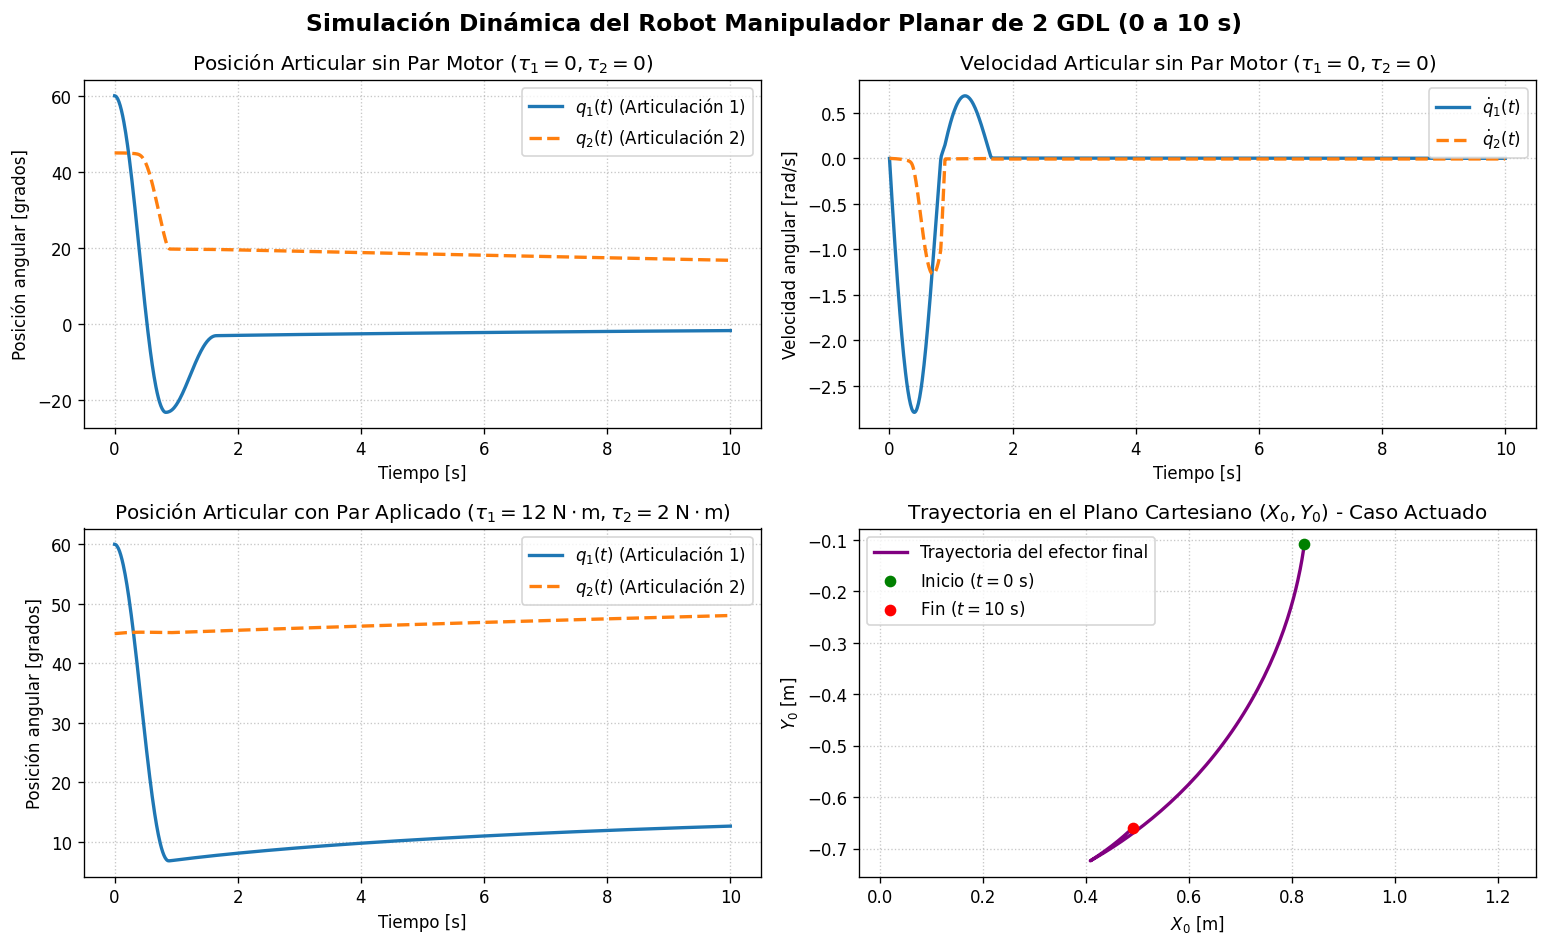

In [1]:
# ==============================================================================
# AF 4: PIA
# ==============================================================================

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# 1. Parámetros físicos del robot planar de 2 GDL (Tabla 5.1)
m1 = 23.902   # Masa eslabón 1 [kg]
m2 = 3.880    # Masa eslabón 2 [kg]
l1 = 0.450    # Longitud eslabón 1 [m]
l2 = 0.450    # Longitud eslabón 2 [m]
lc1 = 0.091   # Centro de masa eslabón 1 [m]
lc2 = 0.048   # Centro de masa eslabón 2 [m]
I1 = 1.266    # Momento de inercia eslabón 1 [kg*m^2]
I2 = 0.093    # Momento de inercia eslabón 2 [kg*m^2]
b1 = 2.288    # Fricción viscosa articulación 1 [N*m*s/rad]
b2 = 0.175    # Fricción viscosa articulación 2 [N*m*s/rad]
fc1 = 7.170   # Fricción de Coulomb articulación 1 [N*m]
fc2 = 1.734   # Fricción de Coulomb articulación 2 [N*m]
g = 9.81      # Aceleración gravitacional [m/s^2]

# 2. Definición de las matrices dinámicas M(q), C(q, dq), g(q) y f(dq)
def matrices_dinamicas(q, dq):
    q1, q2 = q
    dq1, dq2 = dq

    # Matriz de Inercia M(q)
    M11 = m1 * lc1**2 + m2 * l1**2 + m2 * lc2**2 + 2 * m2 * l1 * lc2 * np.cos(q2) + I1 + I2
    M12 = m2 * lc2**2 + m2 * l1 * lc2 * np.cos(q2) + I2
    M21 = M12
    M22 = m2 * lc2**2 + I2
    M = np.array([[M11, M12],
                  [M21, M22]])

    # Matriz de Coriolis y fuerzas centrípetas C(q, dq)
    h = -m2 * l1 * lc2 * np.sin(q2)
    C = np.array([[h * dq2, h * (dq1 + dq2)],
                  [-h * dq1, 0.0]])

    # Vector de pares gravitacionales g(q)
    g1 = (m1 * lc1 + m2 * l1) * g * np.sin(q1) + m2 * lc2 * g * np.sin(q1 + q2)
    g2 = m2 * lc2 * g * np.sin(q1 + q2)
    G = np.array([g1, g2])

    # Vector de fricción f(dq): viscosa + Coulomb (suavizada con tanh para estabilidad numérica)
    B = np.diag([b1, b2])
    Fc = np.array([fc1 * np.tanh(50.0 * dq1),
                   fc2 * np.tanh(50.0 * dq2)])
    F = B @ dq + Fc

    return M, C, G, F

# 3. Modelo en espacio de estados: dx/dt = f(t, x)
def dinamica_robot(t, x, tau_func):
    q = x[0:2]
    dq = x[2:4]
    tau = tau_func(t, q, dq)

    M, C, G, F = matrices_dinamicas(q, dq)
    ddq = np.linalg.solve(M, tau - C @ dq - G - F)

    return np.concatenate([dq, ddq])

# 4. Configuración de la simulación (t = 0 a 10 segundos)
t_span = (0.0, 10.0)
t_eval = np.linspace(0.0, 10.0, 1000)

# Condiciones iniciales: q1(0) = 60° (pi/3 rad), q2(0) = 45° (pi/4 rad), velocidades = 0
x0 = np.array([np.pi / 3, np.pi / 4, 0.0, 0.0])

# Caso A: Respuesta libre con fricción (tau = [0, 0] N*m)
sol_libre = solve_ivp(
    dinamica_robot, t_span, x0, t_eval=t_eval,
    args=(lambda t, q, dq: np.array([0.0, 0.0]),),
    method='RK45', rtol=1e-8, atol=1e-10
)

# Caso B: Respuesta con pares motores aplicados (tau = [12.0, 2.0] N*m)
sol_actuado = solve_ivp(
    dinamica_robot, t_span, x0, t_eval=t_eval,
    args=(lambda t, q, dq: np.array([12.0, 2.0]),),
    method='RK45', rtol=1e-8, atol=1e-10
)

# 5. Visualización de resultados
fig, axs = plt.subplots(2, 2, figsize=(13, 8), dpi=120)
fig.suptitle('Simulación Dinámica del Robot Manipulador Planar de 2 GDL (0 a 10 s)', fontsize=14, fontweight='bold')

# Gráfica 1: Posición articular - Respuesta libre (tau = 0)
axs[0, 0].plot(sol_libre.t, np.rad2deg(sol_libre.y[0]), label=r'$q_1(t)$ (Articulación 1)', linewidth=2)
axs[0, 0].plot(sol_libre.t, np.rad2deg(sol_libre.y[1]), '--', label=r'$q_2(t)$ (Articulación 2)', linewidth=2)
axs[0, 0].set_title(r'Posición Articular sin Par Motor ($\tau_1 = 0, \tau_2 = 0$)')
axs[0, 0].set_xlabel('Tiempo [s]')
axs[0, 0].set_ylabel('Posición angular [grados]')
axs[0, 0].grid(True, linestyle=':', alpha=0.7)
axs[0, 0].legend()

# Gráfica 2: Velocidad articular - Respuesta libre
axs[0, 1].plot(sol_libre.t, sol_libre.y[2], label=r'$\dot{q}_1(t)$', linewidth=2)
axs[0, 1].plot(sol_libre.t, sol_libre.y[3], '--', label=r'$\dot{q}_2(t)$', linewidth=2)
axs[0, 1].set_title(r'Velocidad Articular sin Par Motor ($\tau_1 = 0, \tau_2 = 0$)')
axs[0, 1].set_xlabel('Tiempo [s]')
axs[0, 1].set_ylabel('Velocidad angular [rad/s]')
axs[0, 1].grid(True, linestyle=':', alpha=0.7)
axs[0, 1].legend()

# Gráfica 3: Posición articular - Con par motor constante
axs[1, 0].plot(sol_actuado.t, np.rad2deg(sol_actuado.y[0]), label=r'$q_1(t)$ (Articulación 1)', linewidth=2)
axs[1, 0].plot(sol_actuado.t, np.rad2deg(sol_actuado.y[1]), '--', label=r'$q_2(t)$ (Articulación 2)', linewidth=2)
axs[1, 0].set_title(r'Posición Articular con Par Aplicado ($\tau_1 = 12\;\mathrm{N\cdot m}, \tau_2 = 2\;\mathrm{N\cdot m}$)')
axs[1, 0].set_xlabel('Tiempo [s]')
axs[1, 0].set_ylabel('Posición angular [grados]')
axs[1, 0].grid(True, linestyle=':', alpha=0.7)
axs[1, 0].legend()

# Gráfica 4: Trayectoria cartesiana del extremo final (Caso B)
q1_act, q2_act = sol_actuado.y[0], sol_actuado.y[1]
x_ef = l1 * np.sin(q1_act) + l2 * np.sin(q1_act + q2_act)
y_ef = -l1 * np.cos(q1_act) - l2 * np.cos(q1_act + q2_act)
axs[1, 1].plot(x_ef, y_ef, color='purple', linewidth=2, label='Trayectoria del efector final')
axs[1, 1].scatter([x_ef[0]], [y_ef[0]], color='green', zorder=5, label='Inicio ($t=0$ s)')
axs[1, 1].scatter([x_ef[-1]], [y_ef[-1]], color='red', zorder=5, label='Fin ($t=10$ s)')
axs[1, 1].set_title('Trayectoria en el Plano Cartesiano $(X_0, Y_0)$ - Caso Actuado')
axs[1, 1].set_xlabel('$X_0$ [m]')
axs[1, 1].set_ylabel('$Y_0$ [m]')
axs[1, 1].axis('equal')
axs[1, 1].grid(True, linestyle=':', alpha=0.7)
axs[1, 1].legend()

plt.tight_layout()
plt.show()